In [ ]:
folder_path = '/Users/allisonpickle/Desktop/Image Processing Pipeline Analysis/260212_Threshold Test'

In [ ]:
def Threshold_Test(folder_path, save_output=True):
    import os
    from skimage import io
    from skimage.filters import try_all_threshold
    import matplotlib.pyplot as plt
    """Test threshold options for images in a folder

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the images
    save_output : bool, optional
        If True, save the threshold comparison plots to a subfolder (default: True)

    Returns
    -------
    None
    """
    # Create output folder if saving is enabled
    if save_output:
        output_folder = os.path.join(folder_path, "Threshold_Test")
        os.makedirs(output_folder, exist_ok=True)
        print(f"Output will be saved to: {output_folder}")
    
    # Get a list of all image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff') or file.endswith('.tif')]
    
    print(f"Found {len(image_files)} images to process")

    # Iterate over each image file
    for idx, image_file in enumerate(image_files, 1):
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        # Read the image
        img = io.imread(image_path)
        fig, ax = try_all_threshold(img, figsize=(20, 18), verbose=False)
        plt.suptitle(image_file, fontsize=16, y=0.995)  # Add the image file name as the title
        
        # Save the figure if enabled
        if save_output:
            # Create output filename (replace extension with .png)
            output_filename = os.path.splitext(image_file)[0] + "_thresholds.png"
            output_path = os.path.join(output_folder, output_filename)
            
            plt.savefig(output_path, dpi=150, bbox_inches='tight')
            print(f"[{idx}/{len(image_files)}] Saved: {output_filename}")
        
        plt.show()
        plt.close(fig)  # Close figure to free memory

    if save_output:
        print(f"\nAll threshold tests saved to: {output_folder}")

# Example usage:
Threshold_Test(folder_path)  # Saves output by default
# Threshold_Test(folder_path, save_output=False)  # Display only, don't save

Before use: Isolate microglia channel into a new folder for processing

Autocrop microglia of interest for morphology assessment

In [ ]:
def Crop_Microglia(input_image_path, output_folder, padding=20, min_size_microns=250):
    """
    Takes an input image ending in _C_0.tiff and crops the image around each individual 
    thresholded object using Li thresholding. Only crops objects that meet a minimum size
    determined by the user. If more than 5 objects exist, randomly selects 5 to process.
    Skips objects touching the edges of the image. Saves each cropped object as a separate
    image in the specified output folder with a _#_ added before the _C_0 in the filename.
    """
    import cv2
    import os
    import numpy as np
    import random
    from skimage.measure import regionprops, label as skimage_label
    from skimage.filters import threshold_li
    
    # Scale for converting microns² to pixels
    scale = 0.641  # microns per pixel
    min_size_pixels = int(min_size_microns / (scale ** 2))

    # Load the input _C_0 image
    image_c0 = cv2.imread(input_image_path, cv2.IMREAD_GRAYSCALE)
    if image_c0 is None:
        raise ValueError(f"Error: Unable to load image at {input_image_path}")

    # Apply Li thresholding (no blur step)
    try:
        li_thresh = threshold_li(image_c0)
        binary_image = image_c0 > li_thresh
        binary_image = (binary_image * 255).astype(np.uint8)
    except Exception as e:
        print(f"Error: Li thresholding failed for {input_image_path}: {e}")
        return

    # Label connected components in the binary image
    labeled_image = skimage_label(binary_image)

    # Get properties of labeled regions
    props = regionprops(labeled_image)

    if not props:
        print(f"Warning: No regions found in {input_image_path}. Skipping.")
        return

    # Filter out objects that do not meet the minimum size
    filtered_props = [region for region in props if region.area >= min_size_pixels]

    if not filtered_props:
        print(f"Warning: No regions meet minimum size in {input_image_path}. Skipping.")
        return

    # Randomly select up to 5 objects if more than 5 exist
    if len(filtered_props) > 5:
        filtered_props = random.sample(filtered_props, 5)
        print(f"Randomly selected 5 objects out of {len(filtered_props)} filtered objects.")

    # Get the base filename of the input image
    base_filename_c0 = os.path.basename(input_image_path)

    # Iterate through the selected regions and crop the images
    for i, region in enumerate(filtered_props):
        min_row, min_col, max_row, max_col = region.bbox

        # Skip objects touching the edges of the image
        if min_row == 0 or min_col == 0 or max_row == image_c0.shape[0] or max_col == image_c0.shape[1]:
            print(f"Skipping object {i + 1} - touching the edge of the image.")
            continue

        # Add padding to the bounding box
        min_row = max(min_row - padding, 0)
        min_col = max(min_col - padding, 0)
        max_row = min(max_row + padding, image_c0.shape[0])
        max_col = min(max_col + padding, image_c0.shape[1])

        # Crop the _C_0 image around the padded bounding box
        cropped_image_c0 = image_c0[min_row:max_row, min_col:max_col]

        # Construct the new filename with _#_ added before _C_0
        new_filename_c0 = base_filename_c0.replace("_C_0", f"_{i + 1}_C_0")

        # Save the cropped _C_0 image in the output folder
        output_path_c0 = os.path.join(output_folder, new_filename_c0)
        cv2.imwrite(output_path_c0, cropped_image_c0)
        print(f"Saved cropped _C_0 image: {output_path_c0}")


def Isolate_Microglia(input_folder, padding=20, min_size_microns=100):
    """
    Processes all images in a folder that end with _C_0.tiff for microglia (single-channel).
    Uses Li thresholding for segmentation without image blurring.
    Automatically creates an 'Isolated microglia' folder inside input_folder.
    """
    import os

    print(f"Checking folder: {input_folder}")
    print(f"Folder exists: {os.path.exists(input_folder)}")
    print(f"Is directory: {os.path.isdir(input_folder)}")
    
    # List all files in the folder
    all_files = os.listdir(input_folder)
    print(f"\nTotal files in folder: {len(all_files)}")
    
    # Find files ending with _C_0.tiff
    c0_files = [f for f in all_files if f.endswith("_C_0.tiff")]
    print(f"Files ending with '_C_0.tiff': {len(c0_files)}")
    
    if c0_files:
        print(f"\nFound {len(c0_files)} _C_0.tiff files:")
        for f in c0_files[:10]:  # Show first 10
            print(f"  - {f}")
        if len(c0_files) > 10:
            print(f"  ... and {len(c0_files) - 10} more")
    else:
        print("\n❌ No files ending with '_C_0.tiff' found!")
        print("\nFiles in folder (first 20):")
        for f in all_files[:20]:
            print(f"  - {f}")
        if len(all_files) > 20:
            print(f"  ... and {len(all_files) - 20} more")
        return

    output_folder = os.path.join(input_folder, "Isolated microglia")
    os.makedirs(output_folder, exist_ok=True)
    print(f"\nOutput folder: {output_folder}")
    print("="*80)

    for file_name in c0_files:
        print(f"\nProcessing: {file_name}")
        input_image_path = os.path.join(input_folder, file_name)
        Crop_Microglia(input_image_path, output_folder,
                       padding=padding, min_size_microns=min_size_microns)
    
    print("\n" + "="*80)
    print("Processing complete!")
            
# Example usage:
input_folder = '/Users/allisonpickle/Desktop/Image Processing Pipeline Analysis'
Isolate_Microglia(input_folder, padding=20, min_size_microns=250)

In [ ]:
def sync_isolated_microglia_folders(main_directory, reference_folder_name='sigma_3', dry_run=True):
    """
    Synchronizes Isolated Microglia folders across all sigma_* subfolders to match
    the reference folder (default: sigma_3). Deletes images from other folders if they
    don't exist in the reference folder.
    
    Directory structure expected:
    main_directory/
    ├── sigma_1/
    │   └── Isolated Microglia/
    │       ├── image1_1_C_0.tiff
    │       └── image1_2_C_0.tiff
    ├── sigma_3/
    │   └── Isolated Microglia/
    │       └── image1_1_C_0.tiff  (image1_2 was deleted)
    └── ...
    
    Parameters:
    -----------
    main_directory : str
        Path to the main directory containing sigma_* subfolders
    reference_folder_name : str, optional
        Name of the reference folder to use as the standard (default: 'sigma_3')
    dry_run : bool, optional
        If True, only shows what would be deleted without actually deleting.
        If False, performs the actual deletion. (default: True for safety)
    
    Returns:
    --------
    summary : dict
        Dictionary containing deletion summary information
    """
    import os
    
    print(f"\n{'='*80}")
    print(f"SYNCHRONIZING ISOLATED MICROGLIA FOLDERS")
    print(f"{'='*80}\n")
    print(f"Main directory: {main_directory}")
    print(f"Reference folder: {reference_folder_name}")
    print(f"Mode: {'DRY RUN (preview only)' if dry_run else 'DELETION MODE (will delete files)'}")
    print()
    
    # Verify main directory exists
    if not os.path.exists(main_directory):
        print(f"❌ ERROR: Main directory not found: {main_directory}")
        return None
    
    # Find the reference folder
    reference_folder_path = None
    reference_isolated_path = None
    
    for item in os.listdir(main_directory):
        item_path = os.path.join(main_directory, item)
        if os.path.isdir(item_path) and item == reference_folder_name:
            reference_folder_path = item_path
            reference_isolated_path = os.path.join(item_path, 'Isolated Microglia')
            break
    
    if reference_folder_path is None:
        print(f"❌ ERROR: Reference folder '{reference_folder_name}' not found in {main_directory}")
        return None
    
    if not os.path.exists(reference_isolated_path):
        print(f"❌ ERROR: 'Isolated Microglia' folder not found in {reference_folder_path}")
        return None
    
    print(f"✓ Found reference folder: {reference_folder_path}")
    print(f"✓ Reference Isolated Microglia: {reference_isolated_path}")
    print()
    
    # Get list of images in reference folder
    try:
        reference_images = set(os.listdir(reference_isolated_path))
        reference_images = {f for f in reference_images 
                           if f.lower().endswith(('.tif', '.tiff', '.png', '.jpg'))}
    except Exception as e:
        print(f"❌ ERROR: Unable to read reference folder: {e}")
        return None
    
    print(f"Reference folder contains {len(reference_images)} image(s)")
    print(f"{'─'*80}")
    print(f"Reference images:")
    for img in sorted(reference_images):
        print(f"  ✓ {img}")
    print(f"{'─'*80}\n")
    
    # Track statistics
    folders_processed = 0
    total_images_deleted = 0
    deletion_details = {}
    
    # Find all other sigma folders
    sigma_folders = []
    for item in os.listdir(main_directory):
        item_path = os.path.join(main_directory, item)
        if os.path.isdir(item_path) and item.startswith('sigma_') and item != reference_folder_name:
            isolated_path = os.path.join(item_path, 'Isolated Microglia')
            if os.path.exists(isolated_path):
                sigma_folders.append((item, item_path, isolated_path))
    
    if not sigma_folders:
        print("⚠️  No other sigma folders found to synchronize")
        return {
            'reference_folder': reference_folder_path,
            'reference_images': list(reference_images),
            'folders_processed': 0,
            'images_deleted': 0,
            'deletion_details': {}
        }
    
    print(f"Found {len(sigma_folders)} other sigma folder(s) to synchronize:")
    for folder_name, _, _ in sigma_folders:
        print(f"  - {folder_name}")
    print()
    
    # Process each folder
    for folder_name, folder_path, isolated_path in sorted(sigma_folders):
        print(f"{'='*80}")
        print(f"Processing: {folder_name}")
        print(f"{'='*80}")
        
        try:
            # Get list of images in this folder
            current_images = set(os.listdir(isolated_path))
            current_images = {f for f in current_images 
                            if f.lower().endswith(('.tif', '.tiff', '.png', '.jpg'))}
            
            print(f"Current folder contains {len(current_images)} image(s)")
            
            # Find images that exist here but not in reference
            images_to_delete = current_images - reference_images
            
            if not images_to_delete:
                print(f"✓ Already synchronized - no images to delete")
                folders_processed += 1
            else:
                print(f"⚠️  Found {len(images_to_delete)} image(s) to delete:")
                
                deleted_images = []
                
                for img in sorted(images_to_delete):
                    img_path = os.path.join(isolated_path, img)
                    
                    if dry_run:
                        print(f"  [DRY RUN] Would delete: {img}")
                        deleted_images.append(img)
                    else:
                        try:
                            os.remove(img_path)
                            print(f"  ✗ Deleted: {img}")
                            deleted_images.append(img)
                            total_images_deleted += 1
                        except Exception as e:
                            print(f"  ❌ Error deleting {img}: {e}")
                
                deletion_details[folder_name] = deleted_images
                folders_processed += 1
            
            print()
            
        except Exception as e:
            print(f"❌ Error processing {folder_name}: {e}")
            import traceback
            traceback.print_exc()
            print()
    
    # Summary
    print(f"{'='*80}")
    print(f"SYNCHRONIZATION {'PREVIEW' if dry_run else 'COMPLETE'}")
    print(f"{'='*80}")
    print(f"Reference folder: {os.path.basename(reference_folder_path)}")
    print(f"Reference images: {len(reference_images)}")
    print(f"Folders processed: {folders_processed}")
    
    if dry_run:
        print(f"Images that WOULD BE deleted: {sum(len(imgs) for imgs in deletion_details.values())}")
    else:
        print(f"Images deleted: {total_images_deleted}")
    
    if deletion_details:
        print(f"\nDeletion breakdown:")
        for folder, images in sorted(deletion_details.items()):
            print(f"  {folder}: {len(images)} image(s)")
            for img in sorted(images)[:5]:
                print(f"    - {img}")
            if len(images) > 5:
                print(f"    ... and {len(images) - 5} more")
    else:
        print(f"\n✓ All folders already synchronized!")
    
    if dry_run:
        print(f"\n⚠️  DRY RUN MODE - No files were actually deleted")
        print(f"   Run with dry_run=False to perform actual deletion")
    
    print(f"{'='*80}\n")
    
    return {
        'reference_folder': reference_folder_path,
        'reference_images': list(reference_images),
        'folders_processed': folders_processed,
        'images_deleted': total_images_deleted if not dry_run else 0,
        'deletion_details': deletion_details,
        'dry_run': dry_run
    }


# Example usage:
summary = sync_isolated_microglia_folders(
    main_directory='/Users/allisonpickle/Desktop/Gaussian Test',
    reference_folder_name='sigma_0',
    dry_run=True  # Preview first
)

# Then run with dry_run=False to actually delete
summary = sync_isolated_microglia_folders(
    main_directory='/Users/allisonpickle/Desktop/Gaussian Test',
    reference_folder_name='sigma_3',
    dry_run=False
)

In [15]:
def Measure_Thresholded_Morphology(thresholded_image_path, output_name="BASELINE", generate_images=True):
    """
    Measure microglia morphology on already-thresholded binary images.
    Does NOT apply any thresholding - assumes images are already binary (black/white).
    
    Parameters
    ----------
    thresholded_image_path : str
        Path to folder containing already-thresholded binary images
    output_name : str, optional
        Name for the output Excel file (default: "BASELINE")
    generate_images : bool, optional
        If True, generate contour overlay images. If False, only generate Excel file (default: True)
    
    Returns
    -------
    pd.DataFrame
        DataFrame with morphology results including averages
    """
    import os
    import numpy as np
    import matplotlib.pyplot as plt
    from skimage import measure, io
    from skimage.morphology import binary_closing, disk, convex_hull_image
    from skimage.measure import regionprops, label, perimeter
    import pandas as pd
    import math
    from scipy.ndimage import center_of_mass

    def calculate_inertia_tensor(binary_image):
        """
        Calculate the inertia tensor of a binary image based on its center of mass.
        """
        com = center_of_mass(binary_image)
        y_indices, x_indices = np.indices(binary_image.shape)
        x_distances = x_indices - com[1]
        y_distances = y_indices - com[0]
        Ixx = np.sum(binary_image * y_distances**2)
        Iyy = np.sum(binary_image * x_distances**2)
        Ixy = -np.sum(binary_image * x_distances * y_distances)
        return np.array([[Ixx, Ixy], [Ixy, Iyy]])

    def calculate_aspect_ratio(eigenvalues):
        """
        Calculate the aspect ratio as the square root of the ratio of the largest to the smallest eigenvalue.
        """
        return np.sqrt(np.max(eigenvalues) / np.min(eigenvalues))

    # Set scale for 20x Objective
    scale = 0.335  # microns per pixel

    # VERIFY FOLDER EXISTS
    if not os.path.exists(thresholded_image_path):
        print(f"❌ ERROR: Folder does not exist: {thresholded_image_path}")
        return None

    # Get a list of ALL image files (PNG, TIF, TIFF)
    image_files = [file for file in os.listdir(thresholded_image_path) 
                   if file.lower().endswith(('.png', '.tif', '.tiff'))]
    
    if len(image_files) == 0:
        print(f"❌ ERROR: No image files (.png, .tif, .tiff) found in: {thresholded_image_path}")
        return None
    
    print(f"{'='*80}")
    print(f"PROCESSING THRESHOLDED IMAGES: {output_name}")
    print(f"{'='*80}")
    print(f"Input folder: {thresholded_image_path}")
    print(f"Found {len(image_files)} images to process")
    print(f"File types: {', '.join(set([os.path.splitext(f)[1] for f in image_files]))}")
    print(f"Image generation: {'ENABLED' if generate_images else 'DISABLED (Excel only)'}")
    print(f"{'='*80}\n")

    # Create output folder for contours if generating images
    contours_folder = None
    if generate_images:
        contours_folder = os.path.join(thresholded_image_path, f"Contours_{output_name}")
        os.makedirs(contours_folder, exist_ok=True)
        print(f"Contour images will be saved to: {contours_folder}\n")

    results = []
    
    for image_file in image_files:
        print(f"Processing: {image_file}")
        
        # Construct the full path to the image file
        img_path = os.path.join(thresholded_image_path, image_file)
        
        # Open the image file and convert to grayscale
        image = io.imread(img_path, as_gray=True)
        
        # Simple binarization for already-thresholded images (no re-thresholding)
        binary_image = image > 0.5
        
        # Perform binary closing to fill small holes
        binary_image = binary_closing(binary_image, disk(3))
        
        # Label connected components
        labeled_image = label(binary_image)
        properties = regionprops(labeled_image)
        
        if not properties:
            print(f"  ⚠️  Warning: No regions found. Skipping.")
            continue
        
        # Find the largest connected component
        largest_region = max(properties, key=lambda x: x.area)
        
        # Calculate the convex hull
        convex_hull = convex_hull_image(labeled_image == largest_region.label)
        
        # Calculate metrics
        convex_hull_perimeter_pixels = perimeter(convex_hull)
        convex_hull_perimeter_microns = convex_hull_perimeter_pixels * scale
        convex_hull_area_pixels = np.sum(convex_hull)
        convex_hull_area_microns = convex_hull_area_pixels * (scale ** 2)
        
        area_pixels = largest_region.area
        perimeter_pixels = largest_region.perimeter
        area_microns = area_pixels * (scale ** 2)
        perimeter_microns = perimeter_pixels * scale
        
        # Circularity
        circularity = (4 * math.pi * area_microns) / (perimeter_microns ** 2) if perimeter_microns > 0 else 0
        
        # Aspect ratio
        binary_region = labeled_image == largest_region.label
        inertia_tensor = calculate_inertia_tensor(binary_region)
        eigenvalues, eigenvectors = np.linalg.eigh(inertia_tensor)
        aspect_ratio = calculate_aspect_ratio(eigenvalues)
        
        # Roughness
        roughness = perimeter_microns / convex_hull_perimeter_microns if convex_hull_perimeter_microns > 0 else 0
        
        # Extract base name - handle different naming conventions
        # Try splitting by underscore first
        name_parts = os.path.splitext(image_file)[0].split('_')
        if len(name_parts) >= 3:
            base_name = "_".join(name_parts[:3])
        else:
            # If not enough underscores, use filename without extension
            base_name = os.path.splitext(image_file)[0]
        
        print(f"  ✓ Area: {area_microns:.2f} µm², Circularity: {circularity:.4f}, Roughness: {roughness:.4f}")
        
        # Store results
        result_dict = {
            "File": image_file,
            "Base Name": base_name,
            "Threshold_Method": output_name,
            "Area (µm²)": area_microns,
            "Perimeter (µm)": perimeter_microns,
            "Convex Hull Area (µm²)": convex_hull_area_microns,
            "Convex Hull Perimeter (µm)": convex_hull_perimeter_microns,
            "Circularity": circularity,
            "Aspect Ratio": aspect_ratio,
            "Roughness": roughness
        }
        results.append(result_dict)
        
        # Generate contour overlay image if requested
        if generate_images:
            fig, ax = plt.subplots(figsize=(10, 10))
            ax.imshow(image, cmap='gray')
            
            # Find contours for the largest region
            contours = measure.find_contours(labeled_image == largest_region.label, 0.5)
            
            # Plot the contours in red
            for contour in contours:
                ax.plot(contour[:, 1], contour[:, 0], linewidth=2, color='red')
            
            # Plot the convex hull in green
            convex_hull_coords = np.argwhere(convex_hull)
            for coord in convex_hull_coords:
                ax.plot(coord[1], coord[0], 'o', markersize=1, color='green')
            
            ax.axis('off')
            
            # Save with same extension as input
            output_filename = f"{os.path.splitext(image_file)[0]}_contours{os.path.splitext(image_file)[1]}"
            output_path = os.path.join(contours_folder, output_filename)
            plt.savefig(output_path, dpi=150, bbox_inches='tight', pad_inches=0)
            plt.close(fig)
    
    # Convert to DataFrame
    results_df = pd.DataFrame(results)
    
    if len(results_df) == 0:
        print("\n⚠️  WARNING: No results generated! Check your images.")
        return None
    
    print(f"\nCalculating averages...")
    
    # Calculate averages by base name
    numeric_columns = results_df.select_dtypes(include=[np.number]).columns
    averages_df = results_df.groupby("Base Name")[numeric_columns].mean().reset_index()
    
    # Merge averages back into original DataFrame
    results_with_averages = results_df.merge(averages_df, on="Base Name", suffixes=("", " (Avg)"))
    
    # Ensure averages are only populated once per base name
    results_with_averages.loc[results_with_averages.duplicated(subset=["Base Name"]), 
                               [col + " (Avg)" for col in numeric_columns]] = ""
    
    # Export to Excel - FULL PATH PRINTED
    excel_output_path = os.path.join(thresholded_image_path, f"Morphology_Results_{output_name}.xlsx")
    
    print(f"\nSaving Excel file...")
    print(f"EXACT PATH: {excel_output_path}")
    
    try:
        results_with_averages.to_excel(excel_output_path, index=False)
        print(f"✅ FILE SAVED SUCCESSFULLY!")
    except Exception as e:
        print(f"❌ ERROR SAVING FILE: {e}")
        return None
    
    # VERIFY FILE EXISTS
    if os.path.exists(excel_output_path):
        file_size = os.path.getsize(excel_output_path)
        print(f"✅ FILE CONFIRMED: {file_size} bytes")
    else:
        print(f"❌ FILE NOT FOUND AFTER SAVE ATTEMPT!")
    
    print(f"\n{'='*80}")
    print(f"✓ COMPLETE: Processed {len(results)} images")
    print(f"✓ Results exported to: {excel_output_path}")
    if generate_images and contours_folder:
        image_count = len([f for f in os.listdir(contours_folder) if f.lower().endswith(('.png', '.tif', '.tiff'))])
        print(f"✓ {image_count} contour images saved to: {contours_folder}")
    print(f"{'='*80}\n")
    
    return results_with_averages


# Example usage:
result = Measure_Thresholded_Morphology(
    '/Users/allisonpickle/Desktop/Threshold Comparison Table/Baseline_Thresholded_Images',
    output_name='BASELINE',
    generate_images=False
)

print("\n🔍 CHECKING RESULT:")
if result is not None:
    print(f"✅ DataFrame returned with {len(result)} rows")
    print(result.head())
else:
    print("❌ Function returned None - check error messages above")

PROCESSING THRESHOLDED IMAGES: BASELINE
Input folder: /Users/allisonpickle/Desktop/Threshold Comparison Table/Baseline_Thresholded_Images
Found 213 images to process
File types: .png
Image generation: DISABLED (Excel only)

Processing: 260203_Tri_5ugLPS_04_5_C_0.png
  ✓ Area: 1243.45 µm², Circularity: 0.1467, Roughness: 1.5507
Processing: 251104_Tri_5ugLPS_11_4_C_0.png
  ✓ Area: 322.87 µm², Circularity: 0.7959, Roughness: 1.0244
Processing: 240623_Tri_Ctrl_9_2_C_0.png
  ✓ Area: 596.03 µm², Circularity: 0.4343, Roughness: 1.0763
Processing: 260203_Tri_Ctrl_12_4_C_0.png
  ✓ Area: 472.24 µm², Circularity: 0.8543, Roughness: 1.0033
Processing: 260203_Tri_Ctrl_09_3_C_0.png
  ✓ Area: 475.83 µm², Circularity: 0.4448, Roughness: 1.1315
Processing: 240623_Tri_Ctrl_5_1_C_0.png
  ✓ Area: 162.05 µm², Circularity: 0.8403, Roughness: 1.0080
Processing: 260203_Tri_5ugLPS_07_1_C_0.png
  ✓ Area: 1360.73 µm², Circularity: 0.1948, Roughness: 1.6865
Processing: 240623_Tri_5ugLPS_9_3_C_0.png
  ✓ Area: 688.

/var/folders/9q/b735k4x1335_j77np9rz8xlc0000gn/T/ipykernel_55045/4118761804.py:203: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  results_with_averages.loc[results_with_averages.duplicated(subset=["Base Name"]),
/var/folders/9q/b735k4x1335_j77np9rz8xlc0000gn/T/ipykernel_55045/4118761804.py:203: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  results_with_averages.loc[results_with_averages.duplicated(subset=["Base Name"]),
/var/folders/9q/b735k4x1335_j77np9rz8xlc0000gn/T/ipykernel_55045/4118761804.py:203: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype

In [ ]:
def Measure_Microglia_Morphology(colorized_image_path, 
                                 threshold_methods=['otsu', 'li', 'yen', 'isodata', 'triangle', 'mean', 'minimum'],
                                 baseline_folder=None,
                                 generate_images=True):
    """
    Measure microglia morphology using multiple threshold methods.
    Creates separate subfolders and Excel files for each threshold method.
    Optionally compares results to baseline thresholded images.
    Automatically processes baseline images if baseline_folder is provided.
    
    Parameters
    ----------
    colorized_image_path : str
        Path to the folder containing the images
    threshold_methods : list
        List of threshold methods to use ['otsu', 'li', 'yen', 'isodata', 'triangle', 'mean', 'minimum']
    baseline_folder : str, optional
        FULL PATH to folder with baseline thresholded images for comparison
        Example: '/Users/allisonpickle/Desktop/Threshold Comparison Table/Baseline_Thresholded_Images'
        If provided, baseline images will be automatically processed and saved to colorized_image_path
    generate_images : bool, optional
        If True, generate contour overlay images. If False, only generate Excel files (default: True)
    
    Returns
    -------
    dict
        Dictionary with results for each threshold method, baseline results, and comparison stats
    """
    import os
    import numpy as np
    import matplotlib.pyplot as plt
    from skimage import measure, io
    from skimage.filters import (threshold_li, threshold_mean, threshold_otsu, 
                                  threshold_yen, threshold_isodata, threshold_triangle, 
                                  threshold_minimum)
    from skimage.morphology import binary_closing, disk, convex_hull_image
    from skimage.measure import regionprops, label, perimeter
    import pandas as pd
    import math
    from scipy.ndimage import center_of_mass

    def calculate_inertia_tensor(binary_image):
        """
        Calculate the inertia tensor of a binary image based on its center of mass.
        """
        com = center_of_mass(binary_image)
        y_indices, x_indices = np.indices(binary_image.shape)
        x_distances = x_indices - com[1]
        y_distances = y_indices - com[0]
        Ixx = np.sum(binary_image * y_distances**2)
        Iyy = np.sum(binary_image * x_distances**2)
        Ixy = -np.sum(binary_image * x_distances * y_distances)
        return np.array([[Ixx, Ixy], [Ixy, Iyy]])

    def calculate_aspect_ratio(eigenvalues):
        """
        Calculate the aspect ratio as the square root of the ratio of the largest to the smallest eigenvalue.
        """
        return np.sqrt(np.max(eigenvalues) / np.min(eigenvalues))

    def compare_to_baseline(test_binary, baseline_binary):
        """
        Compare test thresholded image to baseline and calculate similarity metrics.
        Returns Dice coefficient, Jaccard index, and pixel difference percentage.
        """
        intersection = np.logical_and(test_binary, baseline_binary).sum()
        union = np.logical_or(test_binary, baseline_binary).sum()
        test_sum = test_binary.sum()
        baseline_sum = baseline_binary.sum()
        
        # Dice coefficient (F1 score)
        dice = (2 * intersection) / (test_sum + baseline_sum) if (test_sum + baseline_sum) > 0 else 0
        
        # Jaccard index (IoU)
        jaccard = intersection / union if union > 0 else 0
        
        # Pixel difference percentage
        total_pixels = test_binary.size
        diff_pixels = np.logical_xor(test_binary, baseline_binary).sum()
        diff_percentage = (diff_pixels / total_pixels) * 100
        
        return dice, jaccard, diff_percentage

    def process_images(image_path, image_list, method_name, scale, generate_imgs=True, output_folder=None, is_baseline=False):
        """
        Helper function to process images and calculate morphology metrics.
        """
        if generate_imgs and output_folder:
            os.makedirs(output_folder, exist_ok=True)
        
        results = []
        for image_file in image_list:
            print(f"  Processing: {image_file}")
            
            img_path = os.path.join(image_path, image_file)
            image = io.imread(img_path, as_gray=True)
            
            # For baseline, assume already thresholded (binary images)
            # Just use simple 0.5 threshold since they're already binary
            if is_baseline:
                binary_image = image > 0.5
            else:
                binary_image = image > threshold_mean(image)
            
            # Perform binary closing to fill small holes
            binary_image = binary_closing(binary_image, disk(3))
            
            # Label connected components
            labeled_image = label(binary_image)
            properties = regionprops(labeled_image)
            
            if not properties:
                print(f"    Warning: No regions found. Skipping.")
                continue
            
            # Find the largest connected component
            largest_region = max(properties, key=lambda x: x.area)
            
            # Calculate the convex hull
            convex_hull = convex_hull_image(labeled_image == largest_region.label)
            
            # Calculate metrics
            convex_hull_perimeter_pixels = perimeter(convex_hull)
            convex_hull_perimeter_microns = convex_hull_perimeter_pixels * scale
            convex_hull_area_pixels = np.sum(convex_hull)
            convex_hull_area_microns = convex_hull_area_pixels * (scale ** 2)
            
            area_pixels = largest_region.area
            perimeter_pixels = largest_region.perimeter
            area_microns = area_pixels * (scale ** 2)
            perimeter_microns = perimeter_pixels * scale
            
            # Circularity
            circularity = (4 * math.pi * area_microns) / (perimeter_microns ** 2) if perimeter_microns > 0 else 0
            
            # Aspect ratio
            binary_region = labeled_image == largest_region.label
            inertia_tensor = calculate_inertia_tensor(binary_region)
            eigenvalues, eigenvectors = np.linalg.eigh(inertia_tensor)
            aspect_ratio = calculate_aspect_ratio(eigenvalues)
            
            # Roughness
            roughness = perimeter_microns / convex_hull_perimeter_microns if convex_hull_perimeter_microns > 0 else 0
            
            # Extract base name
            base_name = "_".join(image_file.split('_')[:3])
            
            # Store results
            result_dict = {
                "File": image_file,
                "Base Name": base_name,
                "Threshold_Method": method_name,
                "Area (µm²)": area_microns,
                "Perimeter (µm)": perimeter_microns,
                "Convex Hull Area (µm²)": convex_hull_area_microns,
                "Convex Hull Perimeter (µm)": convex_hull_perimeter_microns,
                "Circularity": circularity,
                "Aspect Ratio": aspect_ratio,
                "Roughness": roughness
            }
            results.append(result_dict)
            
            # Generate contour overlay image if requested
            if generate_imgs and output_folder:
                fig, ax = plt.subplots(figsize=(10, 10))
                ax.imshow(image, cmap='gray')
                
                contours = measure.find_contours(labeled_image == largest_region.label, 0.5)
                for contour in contours:
                    ax.plot(contour[:, 1], contour[:, 0], linewidth=2, color='red')
                
                convex_hull_coords = np.argwhere(convex_hull)
                for coord in convex_hull_coords:
                    ax.plot(coord[1], coord[0], 'o', markersize=1, color='green')
                
                ax.axis('off')
                
                output_path = os.path.join(output_folder, f"{image_file}")
                plt.savefig(output_path, dpi=150, bbox_inches='tight', pad_inches=0)
                plt.close(fig)
        
        return results

    # Set scale for 20x Objective
    scale = 0.335  # microns per pixel

    # Get a list of all TIFF files in the folder that end with _C_0
    image_files = [file for file in os.listdir(colorized_image_path) 
                   if file.endswith('_C_0.tif') or file.endswith('_C_0.tiff')]
    
    print(f"Found {len(image_files)} images to process")
    print(f"Processing with threshold methods: {', '.join([m.upper() for m in threshold_methods])}")
    print(f"Image generation: {'ENABLED' if generate_images else 'DISABLED (Excel only)'}")
    
    # Check if baseline folder exists (now using full path directly)
    baseline_path = None
    baseline_image_files = []
    if baseline_folder:
        baseline_path = baseline_folder  # Use the provided path directly
        if os.path.exists(baseline_path):
            baseline_image_files = [file for file in os.listdir(baseline_path) 
                                   if file.endswith('_C_0.tif') or file.endswith('_C_0.tiff')]
            print(f"✓ Baseline folder found: {baseline_path}")
            print(f"  Found {len(baseline_image_files)} baseline images")
            print(f"  Will automatically process baseline images and save results to: {colorized_image_path}")
        else:
            print(f"⚠️  Baseline folder not found: {baseline_path}")
            print(f"  Proceeding without baseline comparison")
            baseline_folder = None
            baseline_path = None
    
    print(f"{'='*80}\n")

    # Dictionary to store results for each method
    all_results = {}
    comparison_results = []

    # ========== PROCESS BASELINE IMAGES FIRST (if available) ==========
    if baseline_path and baseline_image_files:
        print(f"\n{'#'*80}")
        print(f"# PROCESSING BASELINE IMAGES")
        print(f"{'#'*80}\n")
        
        baseline_contours_folder = None
        if generate_images:
            # Save baseline contours to colorized_image_path (same as other methods)
            baseline_contours_folder = os.path.join(colorized_image_path, "Contours_baseline")
        
        baseline_results = process_images(
            baseline_path, 
            baseline_image_files, 
            "BASELINE", 
            scale, 
            generate_images, 
            baseline_contours_folder,
            is_baseline=True  # FLAG: Don't re-threshold baseline images
        )
        
        # Convert to DataFrame
        baseline_df = pd.DataFrame(baseline_results)
        
        if len(baseline_df) == 0:
            print("⚠️  WARNING: No baseline results generated! Check your baseline images.")
        else:
            # Calculate averages
            numeric_columns = baseline_df.select_dtypes(include=[np.number]).columns
            baseline_averages = baseline_df.groupby("Base Name")[numeric_columns].mean().reset_index()
            baseline_with_averages = baseline_df.merge(baseline_averages, on="Base Name", suffixes=("", " (Avg)"))
            baseline_with_averages.loc[baseline_with_averages.duplicated(subset=["Base Name"]), 
                                       [col + " (Avg)" for col in numeric_columns]] = ""
            
            # Export baseline results to colorized_image_path (SAME LOCATION AS OTHER THRESHOLDS)
            baseline_excel_path = os.path.join(colorized_image_path, "Morphology_Results_BASELINE.xlsx")
            baseline_with_averages.to_excel(baseline_excel_path, index=False)
            print(f"\n✓ Baseline results exported to: {baseline_excel_path}")
            
            if generate_images and baseline_contours_folder:
                print(f"✓ Baseline contour images saved to: {baseline_contours_folder}")
            
            all_results['baseline'] = baseline_with_averages

    # ========== PROCESS THRESHOLD METHODS ==========
    for threshold_method in threshold_methods:
        print(f"\n{'#'*80}")
        print(f"# PROCESSING WITH {threshold_method.upper()} THRESHOLD")
        print(f"{'#'*80}\n")

        # Create method-specific folders only if generating images
        contours_folder = None
        if generate_images:
            contours_folder = os.path.join(colorized_image_path, f"Contours_{threshold_method}")
            os.makedirs(contours_folder, exist_ok=True)

        # Iterate over each image file to calculate measurements
        results = []
        for image_file in image_files:
            print(f"Processing: {image_file} ({threshold_method.upper()})")
            
            # Construct the full path to the image file
            image_path = os.path.join(colorized_image_path, image_file)

            # Open the image file and convert to grayscale
            image = io.imread(image_path, as_gray=True)

            # Apply selected thresholding method
            try:
                if threshold_method.lower() == 'li':
                    thresh = threshold_li(image)
                elif threshold_method.lower() == 'mean':
                    thresh = threshold_mean(image)
                elif threshold_method.lower() == 'otsu':
                    thresh = threshold_otsu(image)
                elif threshold_method.lower() == 'yen':
                    thresh = threshold_yen(image)
                elif threshold_method.lower() == 'isodata':
                    thresh = threshold_isodata(image)
                elif threshold_method.lower() == 'triangle':
                    thresh = threshold_triangle(image)
                elif threshold_method.lower() == 'minimum':
                    thresh = threshold_minimum(image)
                else:
                    raise ValueError(f"Unknown threshold method: {threshold_method}")
                
                binary_image = image > thresh
                print(f"  Threshold value: {thresh:.4f}")
            except Exception as e:
                print(f"  Error: {threshold_method.upper()} thresholding failed: {e}")
                continue

            # Compare to baseline if available
            baseline_comparison = {}
            if baseline_path:
                baseline_image_path = os.path.join(baseline_path, image_file)
                if os.path.exists(baseline_image_path):
                    baseline_image = io.imread(baseline_image_path, as_gray=True)
                    baseline_binary = baseline_image > 0.5  # Use 0.5 for baseline since already binary
                    
                    dice, jaccard, diff_pct = compare_to_baseline(binary_image, baseline_binary)
                    baseline_comparison = {
                        'Dice_Coefficient': dice,
                        'Jaccard_Index': jaccard,
                        'Pixel_Diff_Percent': diff_pct
                    }
                    print(f"  Baseline comparison - Dice: {dice:.4f}, Jaccard: {jaccard:.4f}, Diff: {diff_pct:.2f}%")

            # Perform binary closing to fill small holes
            binary_image = binary_closing(binary_image, disk(3))

            # Label connected components
            labeled_image = label(binary_image)

            # Measure properties of labeled regions
            properties = regionprops(labeled_image)

            if not properties:
                print(f"  Warning: No regions found. Skipping.")
                continue

            # Find the largest connected component (largest white area)
            largest_region = max(properties, key=lambda x: x.area)

            # Calculate the convex hull of the largest region
            convex_hull = convex_hull_image(labeled_image == largest_region.label)

            # Calculate the convex hull perimeter
            convex_hull_perimeter_pixels = perimeter(convex_hull)
            convex_hull_perimeter_microns = convex_hull_perimeter_pixels * scale

            # Convert convex hull area to microns²
            convex_hull_area_pixels = np.sum(convex_hull)
            convex_hull_area_microns = convex_hull_area_pixels * (scale ** 2)

            # Calculate perimeter, area, and convex hull area for the largest region
            area_pixels = largest_region.area
            perimeter_pixels = largest_region.perimeter

            # Convert area and perimeter to microns
            area_microns = area_pixels * (scale ** 2)
            perimeter_microns = perimeter_pixels * scale

            # Calculate circularity
            if perimeter_microns > 0:
                circularity = (4 * math.pi * area_microns) / (perimeter_microns ** 2)
            else:
                circularity = 0

            # Calculate the inertia tensor and aspect ratio
            binary_region = labeled_image == largest_region.label
            inertia_tensor = calculate_inertia_tensor(binary_region)
            eigenvalues, eigenvectors = np.linalg.eigh(inertia_tensor)
            aspect_ratio = calculate_aspect_ratio(eigenvalues)

            # Calculate roughness
            if convex_hull_perimeter_microns > 0:
                roughness = perimeter_microns / convex_hull_perimeter_microns
            else:
                roughness = 0

            # Extract the base name (first three elements separated by underscores)
            base_name = "_".join(image_file.split('_')[:3])

            # Append results
            result_dict = {
                "File": image_file,
                "Base Name": base_name,
                "Threshold_Method": threshold_method.upper(),
                "Threshold_Value": thresh,
                "Area (µm²)": area_microns,
                "Perimeter (µm)": perimeter_microns,
                "Convex Hull Area (µm²)": convex_hull_area_microns,
                "Convex Hull Perimeter (µm)": convex_hull_perimeter_microns,
                "Circularity": circularity,
                "Aspect Ratio": aspect_ratio,
                "Roughness": roughness
            }
            
            # Add baseline comparison if available
            if baseline_comparison:
                result_dict.update(baseline_comparison)
                comparison_results.append({
                    'File': image_file,
                    'Threshold_Method': threshold_method.upper(),
                    **baseline_comparison
                })
            
            results.append(result_dict)

            # Generate contour overlay image only if requested
            if generate_images:
                # Create a figure to display the image with contours
                fig, ax = plt.subplots(figsize=(10, 10))
                ax.imshow(image, cmap='gray')

                # Find contours for the largest region
                contours = measure.find_contours(labeled_image == largest_region.label, 0.5)

                # Plot the contours in red
                for contour in contours:
                    ax.plot(contour[:, 1], contour[:, 0], linewidth=2, color='red')

                # Plot the convex hull in green
                convex_hull_coords = np.argwhere(convex_hull)
                for coord in convex_hull_coords:
                    ax.plot(coord[1], coord[0], 'o', markersize=1, color='green')

                # Remove axis labels and ticks
                ax.axis('off')

                # Save the image with contours and convex hull
                output_path = os.path.join(contours_folder, f"{image_file}")
                plt.savefig(output_path, dpi=150, bbox_inches='tight', pad_inches=0)
                plt.close(fig)

        # Convert results to a DataFrame
        results_df = pd.DataFrame(results)

        # Group by base name and calculate averages for numeric columns only
        numeric_columns = results_df.select_dtypes(include=[np.number]).columns
        averages_df = results_df.groupby("Base Name")[numeric_columns].mean().reset_index()

        # Merge the averages back into the original DataFrame
        results_with_averages = results_df.merge(averages_df, on="Base Name", suffixes=("", " (Avg)"))

        # Ensure averages are only populated once per base name
        results_with_averages.loc[results_with_averages.duplicated(subset=["Base Name"]), 
                                   [col + " (Avg)" for col in numeric_columns]] = ""

        # Export results to a method-specific Excel file
        excel_output_path = os.path.join(
            colorized_image_path, 
            f"Morphology_Results_{threshold_method.upper()}.xlsx"
        )
        results_with_averages.to_excel(excel_output_path, index=False)
        print(f"\n✓ Results exported to {excel_output_path}")
        
        if generate_images:
            print(f"✓ Contour images saved to {contours_folder}")
        
        # Store in dictionary
        all_results[threshold_method] = results_with_averages

    # Export comparison results if available
    if comparison_results:
        comparison_df = pd.DataFrame(comparison_results)
        comparison_excel_path = os.path.join(colorized_image_path, "Baseline_Comparison_Summary.xlsx")
        comparison_df.to_excel(comparison_excel_path, index=False)
        print(f"\n✓ Baseline comparison results exported to {comparison_excel_path}")
        all_results['baseline_comparison'] = comparison_df

    print(f"\n{'='*80}")
    print(f"COMPLETE: {len(threshold_methods)} threshold methods processed")
    if baseline_path and baseline_image_files:
        print(f"          + BASELINE method processed")
    print(f"{'='*80}\n")
    
    # Print summary
    print("Output summary:")
    print(f"\nAll results saved to: {colorized_image_path}\n")
    
    # Baseline results
    if 'baseline' in all_results:
        baseline_excel = os.path.join(colorized_image_path, "Morphology_Results_BASELINE.xlsx")
        print(f"  BASELINE: {baseline_excel}")
        if generate_images:
            baseline_contours = os.path.join(colorized_image_path, "Contours_baseline")
            if os.path.exists(baseline_contours):
                image_count = len([f for f in os.listdir(baseline_contours) if f.endswith(('.tif', '.tiff'))])
                print(f"            {baseline_contours} ({image_count} contour images)")
    
    # Threshold method results
    for method in threshold_methods:
        excel_path = os.path.join(colorized_image_path, f"Morphology_Results_{method.upper()}.xlsx")
        if os.path.exists(excel_path):
            print(f"  {method.upper()}: {excel_path}")
            if generate_images:
                contours_path = os.path.join(colorized_image_path, f"Contours_{method}")
                if os.path.exists(contours_path):
                    image_count = len([f for f in os.listdir(contours_path) if f.endswith(('.tif', '.tiff'))])
                    print(f"           {contours_path} ({image_count} contour images)")
    
    if comparison_results:
        print(f"\n  Baseline comparison: {comparison_excel_path}")
        print(f"           ({len(comparison_results)} comparisons)")

    return all_results

# Example usage - provide FULL SEPARATE PATHS:
Measure_Microglia_Morphology(
    '/Users/allisonpickle/Desktop/Threshold Comparison Table/Isolated microglia',
    threshold_methods=['otsu', 'li', 'yen', 'isodata', 'triangle', 'mean', 'minimum'],
    baseline_folder='/Users/allisonpickle/Desktop/Threshold Comparison Table/Baseline_Thresholded_Images',
    generate_images=False
)

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import defaultdict

def create_composite_images_for_thresholds(main_directory,
                                           threshold_methods=['li', 'mean', 'otsu'],
                                           image_extensions=('.tif', '.tiff', '.png', '.jpg'),
                                           figsize_per_image=(3, 3),
                                           dpi=150):
    """
    Create composite images showing the original isolated microglia image alongside
    its contour versions from different threshold methods (Li, Mean, Otsu).
    
    Structure expected:
      - main_directory/image_C_0.tiff (original isolated microglia images)
      - main_directory/Contours_li/image_C_0.tiff
      - main_directory/Contours_mean/image_C_0.tiff
      - main_directory/Contours_otsu/image_C_0.tiff
    
    Output files saved to:
      - main_directory/Threshold_Comparisons/
    
    Parameters
    ----------
    main_directory : str
        Path to folder containing isolated microglia images and Contours_* subfolders
    threshold_methods : list
        List of threshold method names (default: ['li', 'mean', 'otsu'])
    image_extensions : tuple
        Valid image file extensions
    figsize_per_image : tuple
        Size of each subplot (width, height) in inches
    dpi : int
        Resolution for saved images
    
    Returns
    -------
    dict
        Summary of processing results
    """
    
    def collect_images():
        """Collect all images and organize by base name."""
        # Map: base_name -> {'original': path, 'li': path, 'mean': path, 'otsu': path}
        by_name = defaultdict(dict)
        
        # Collect original images from main directory
        try:
            main_files = [f for f in os.listdir(main_directory)
                         if os.path.isfile(os.path.join(main_directory, f))
                         and any(f.lower().endswith(ext) for ext in image_extensions)]
            
            for f in main_files:
                base = os.path.splitext(f)[0]
                by_name[base]['original'] = os.path.join(main_directory, f)
        except Exception as e:
            print(f"Error reading main directory: {e}")
        
        # Collect contour images from each threshold subfolder
        for method in threshold_methods:
            contour_folder = os.path.join(main_directory, f"Contours_{method}")
            if not os.path.exists(contour_folder):
                print(f"Warning: {contour_folder} not found, skipping {method}")
                continue
            
            try:
                contour_files = [f for f in os.listdir(contour_folder)
                                if any(f.lower().endswith(ext) for ext in image_extensions)]
                
                for f in contour_files:
                    base = os.path.splitext(f)[0]
                    by_name[base][method] = os.path.join(contour_folder, f)
            except Exception as e:
                print(f"Error reading {contour_folder}: {e}")
        
        return by_name
    
    def ensure_output_dir(root):
        """Create output directory."""
        output_dir = os.path.join(root, 'Threshold_Comparisons')
        os.makedirs(output_dir, exist_ok=True)
        return output_dir
    
    def make_composites(by_name, output_dir):
        """Create composite images."""
        # Define column order: original, then threshold methods
        columns = ['original'] + threshold_methods
        column_labels = ['Original'] + [m.upper() for m in threshold_methods]
        
        # Only include images present in ALL columns
        complete = {name: paths for name, paths in by_name.items() 
                   if all(col in paths for col in columns)}
        
        print(f"\nFound {len(complete)} complete image sets (original + all threshold methods)")
        
        if len(complete) == 0:
            print("No complete image sets found. Check that:")
            print(f"  1. Images exist in: {main_directory}")
            print(f"  2. Subfolders exist: {[f'Contours_{m}' for m in threshold_methods]}")
            print(f"  3. File names match across all locations")
            return 0
        
        count = 0
        for base_name, paths in sorted(complete.items()):
            ncols = len(columns)
            fig, axes = plt.subplots(1, ncols,
                                     figsize=(figsize_per_image[0] * ncols, figsize_per_image[1]))
            if ncols == 1:
                axes = [axes]
            
            # Render each column
            for ax_idx, (col, label) in enumerate(zip(columns, column_labels)):
                ax = axes[ax_idx]
                img_path = paths[col]
                
                try:
                    img = Image.open(img_path)
                    arr = np.array(img)
                    if arr.ndim == 2:
                        ax.imshow(arr, cmap='gray')
                    else:
                        ax.imshow(arr)
                except Exception as e:
                    ax.text(0.5, 0.5, f'Error\n{label}', 
                           ha='center', va='center', color='red')
                    print(f"Error loading {img_path}: {e}")
                
                ax.set_title(label, fontsize=12, fontweight='bold', pad=8)
                ax.axis('off')
            
            plt.subplots_adjust(wspace=0.05, hspace=0, 
                              left=0.02, right=0.98, top=0.88, bottom=0.02)
            
            # Save composite
            safe_name = base_name.replace('/', '_').replace('\\', '_')
            out_path = os.path.join(output_dir, f"{safe_name}_comparison.png")
            plt.savefig(out_path, dpi=dpi, bbox_inches='tight', 
                       facecolor='white', edgecolor='none')
            plt.close(fig)
            count += 1
            
            if count % 10 == 0:
                print(f"  Processed {count}/{len(complete)} composites...")
        
        return count
    
    # Main execution
    print(f"Processing threshold comparisons in: {main_directory}")
    print(f"Threshold methods: {', '.join([m.upper() for m in threshold_methods])}")
    print("="*80)
    
    print("\nCollecting images...")
    by_name = collect_images()
    print(f"Found {len(by_name)} unique image base names")
    
    output_dir = ensure_output_dir(main_directory)
    print(f"\nOutput directory: {output_dir}")
    
    print("\nCreating composite images...")
    composite_count = make_composites(by_name, output_dir)
    
    print("\n" + "="*80)
    print(f"COMPLETE: {composite_count} composite images created")
    print(f"Saved to: {output_dir}")
    print("="*80)
    
    return {
        "composite_count": composite_count,
        "output_directory": output_dir,
        "threshold_methods": threshold_methods
    }


# Example usage:
main_dir = '/Users/allisonpickle/Desktop/Image Processing Pipeline Analysis/260212_Threshold Test/Isolated microglia'
create_composite_images_for_thresholds(main_dir)

# Or customize threshold methods:
# create_composite_images_for_thresholds(main_dir, threshold_methods=['li', 'otsu'])

In [ ]:
def Analyze_Gaussian_Sigma_Stats(
    excel_path,
    sheet_name=None,
    output_dir=None,
    expected_sigmas=('0', '1', '2', '3', '4', '5'),
    reference_sigma='0',
    alpha=0.05,
    filter_treatment=None  # Optional: Filter for specific treatment in filename
):
    """
    Performs repeated measures ANOVA on Gaussian filtering (sigma) data from Excel.
    
    Expected Excel structure:
    Column 0: Base Name (microglia identifier)
    Subsequent columns: sigma_0, sigma_1, sigma_2, sigma_3, sigma_4, sigma_5
    
    Performs:
    - Repeated measures ANOVA across sigma values
    - Pairwise t-tests with Bonferroni correction
    - Generates plots and saves statistics
    - Plots individual microglia trajectories across sigma with significance markers
    
    Parameters:
    - excel_path: Path to Excel file
    - sheet_name: Sheet name (None = first sheet)
    - output_dir: Directory for outputs (None = same as Excel)
    - expected_sigmas: Tuple of sigma values (default: '0' to '5')
    - reference_sigma: Reference sigma for comparisons (default: '0' = original)
    - alpha: Significance level (default: 0.05)
    - filter_treatment: Only process rows with this string in Base Name (default: None = all)
    """
    import os
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy import stats
    
    print(f"Reading Excel file: {excel_path}")
    if filter_treatment:
        print(f"Filtering for Base Names containing: '{filter_treatment}'")
    print("=" * 80)
    
    # Load Excel
    if sheet_name is None:
        df = pd.read_excel(excel_path)
        sheet_name = pd.ExcelFile(excel_path).sheet_names[0]
    else:
        df = pd.read_excel(excel_path, sheet_name=sheet_name)
    
    print(f"Sheet: {sheet_name}")
    print(f"Total rows in Excel: {len(df)}")
    
    # Get headers
    headers = list(df.columns)
    basename_col = headers[0]
    
    # Find sigma columns
    sigma_columns = {}
    for i, col in enumerate(headers[1:], 1):
        col_name = str(col).strip().lower()
        if col_name.startswith('sigma_'):
            sigma = col_name[6:]  # Remove 'sigma_' prefix
            if sigma in expected_sigmas:
                sigma_columns[sigma] = col
    
    print(f"Found {len(sigma_columns)} sigma columns: {list(sigma_columns.keys())}")
    
    # Set output directory
    if output_dir is None:
        output_dir = os.path.join(os.path.dirname(excel_path), 
                                   os.path.splitext(os.path.basename(excel_path))[0] + "_Statistics")
    os.makedirs(output_dir, exist_ok=True)
    
    # Filter data if treatment specified
    if filter_treatment:
        df = df[df[basename_col].astype(str).str.contains(filter_treatment, na=False)]
        print(f"Filtered to {len(df)} rows containing '{filter_treatment}'")
    
    # Collect data for each sigma
    data_dict = {}
    for sigma, col in sigma_columns.items():
        values = df[col].dropna().values
        data_dict[sigma] = values
    
    n_microglia = len(df)
    print(f"\nTotal microglia to analyze: {n_microglia}")
    print("=" * 80)
    
    # Descriptive statistics
    print("\nDESCRIPTIVE STATISTICS:")
    print("-" * 80)
    
    stats_summary = []
    for sigma in expected_sigmas:
        if sigma in data_dict:
            values = np.array(data_dict[sigma])
            label = " (original)" if sigma == '0' else ""
            stats_summary.append({
                'Sigma': sigma,
                'Mean': np.mean(values),
                'SD': np.std(values, ddof=1),
                'Min': np.min(values),
                'Max': np.max(values)
            })
            print(f"σ = {sigma:>1}{label}: Mean = {np.mean(values):10.4f}, SD = {np.std(values, ddof=1):10.4f}, "
                  f"Min = {np.min(values):10.4f}, Max = {np.max(values):10.4f}")
    
    # Repeated measures ANOVA
    print("\n" + "=" * 80)
    print("STATISTICAL ANALYSIS RESULTS")
    print("=" * 80)
    
    # Prepare data for ANOVA
    sigma_list = [s for s in expected_sigmas if s in data_dict]
    
    # Perform repeated measures ANOVA
    F_stat, p_value = stats.f_oneway(*[data_dict[s] for s in sigma_list])
    
    print("Repeated Measures ANOVA:")
    print("-" * 80)
    df_between = len(sigma_list) - 1
    df_within = n_microglia * len(sigma_list) - len(sigma_list)
    print(f"F({df_between}, {df_within}) = {F_stat:.4f}")
    print(f"p-value: {p_value:.2e}")
    
    if p_value < 0.001:
        interpretation = "HIGHLY SIGNIFICANT (p < 0.001) ***"
    elif p_value < 0.01:
        interpretation = "SIGNIFICANT (p < 0.01) **"
    elif p_value < 0.05:
        interpretation = "SIGNIFICANT (p < 0.05) *"
    else:
        interpretation = "NOT SIGNIFICANT (p ≥ 0.05) ns"
    
    print(f"Interpretation: {interpretation}")
    
    # Pairwise t-tests with Bonferroni correction
    print(f"\nPairwise paired t-tests vs σ={reference_sigma} (reference):")
    n_comparisons = len(sigma_list) - 1
    bonferroni_alpha = alpha / n_comparisons
    print(f"Bonferroni correction applied for {n_comparisons} comparisons")
    print("-" * 80)
    
    pairwise_results = []
    ref_data = data_dict[reference_sigma]
    
    for sigma in sigma_list:
        if sigma == reference_sigma:
            continue
        
        test_data = data_dict[sigma]
        t_stat, p_val = stats.ttest_rel(ref_data, test_data)
        
        # Significance stars
        if p_val < 0.001:
            sig = "***"
        elif p_val < 0.01:
            sig = "**"
        elif p_val < bonferroni_alpha:
            sig = "*"
        else:
            sig = "ns"
        
        pairwise_results.append({
            'Comparison': f"σ={reference_sigma} vs σ={sigma}",
            'Sigma': sigma,
            't': t_stat,
            'p': p_val,
            'sig': sig
        })
        
        print(f"σ={reference_sigma} vs σ={sigma}: t = {t_stat:7.4f}, p = {p_val:.2e}")
        print(f"Significance: {sig}")
        print("-" * 80)
    
    print("\nSignificance levels: ns (p≥0.05), * (p<0.05), ** (p<0.01), *** (p<0.001)")
    print(f"(Note: Bonferroni correction applied for {n_comparisons} comparisons)")
    
    # Save statistics to file
    stats_file = os.path.join(output_dir, 
                               f"{os.path.splitext(os.path.basename(excel_path))[0]}_Statistics.txt")
    
    with open(stats_file, 'w') as f:
        f.write(f"Gaussian Filtering Analysis\n")
        f.write(f"Number of microglia: {n_microglia}\n")
        if filter_treatment:
            f.write(f"Treatment filter: {filter_treatment}\n")
        f.write("\nDESCRIPTIVE STATISTICS:\n")
        for s in stats_summary:
            label = " (original)" if s['Sigma'] == '0' else ""
            f.write(f"σ = {s['Sigma']}{label}: Mean={s['Mean']:10.4f}, SD={s['SD']:10.4f}, "
                   f"Min={s['Min']:10.4f}, Max={s['Max']:10.4f}\n")
        f.write(f"\nREPEATED MEASURES ANOVA:\n")
        f.write(f"F({df_between}, {df_within}) = {F_stat:.4f}, p = {p_value:.2e}\n")
        f.write(f"{interpretation}\n\n")
        f.write(f"PAIRWISE T-TESTS (Bonferroni corrected):\n")
        for pr in pairwise_results:
            f.write(f"{pr['Comparison']}: t={pr['t']:7.4f}, p={pr['p']:.2e}, {pr['sig']}\n")
    
    print(f"\nStatistics saved to {stats_file}")
    
    # Generate boxplot
    fig, ax = plt.subplots(figsize=(10, 6))
    
    positions = list(range(len(sigma_list)))
    bp = ax.boxplot([data_dict[s] for s in sigma_list], positions=positions,
                    patch_artist=True, widths=0.6)
    
    for patch in bp['boxes']:
        patch.set_facecolor('#2196F3')
        patch.set_alpha(0.7)
    
    ax.set_xticks(positions)
    ax.set_xticklabels([f'σ={s}' for s in sigma_list])
    ax.set_xlabel('Gaussian Filter Sigma', fontsize=12)
    ax.set_ylabel(f'{sheet_name}', fontsize=12)
    title_text = f'Gaussian Filtering Comparison: {sheet_name}\n(n={n_microglia} microglia)'
    if filter_treatment:
        title_text += f' - {filter_treatment}'
    ax.set_title(title_text, fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    plot_file = os.path.join(output_dir,
                            f"{os.path.splitext(os.path.basename(excel_path))[0]}_sigma_comparison.png")
    plt.tight_layout()
    plt.savefig(plot_file, dpi=300)
    plt.close()
    
    print(f"Figure saved to {plot_file}")
    
    # Generate trajectory plot with significance markers
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # X-axis: sigma values as numbers
    x_values = [float(s) for s in sigma_list]
    
    # Plot each microglia as a separate line
    for i in range(n_microglia):
        y_values = [data_dict[s][i] for s in sigma_list]
        ax.plot(x_values, y_values, marker='o', alpha=0.3, linewidth=1, markersize=4, color='gray')
    
    # Add mean line
    mean_values = [np.mean(data_dict[s]) for s in sigma_list]
    ax.plot(x_values, mean_values, color='blue', linewidth=3, marker='s', 
            markersize=8, label='Mean', zorder=100)
    
    # Add significance asterisks above mean line
    y_max = max(mean_values)
    y_range = max([max(data_dict[s]) for s in sigma_list]) - min([min(data_dict[s]) for s in sigma_list])
    annotation_height = y_max + 0.1 * y_range
    
    # Create significance dictionary
    sig_dict = {pr['Sigma']: pr['sig'] for pr in pairwise_results}
    
    for i, sigma in enumerate(sigma_list):
        if sigma in sig_dict and sig_dict[sigma] != 'ns':
            ax.text(x_values[i], annotation_height, sig_dict[sigma], 
                   ha='center', va='bottom', fontsize=14, fontweight='bold', color='black')
    
    ax.set_xlabel('Gaussian Filter Sigma (σ)', fontsize=12)
    ax.set_ylabel(f'{sheet_name}', fontsize=12)
    title_text = f'Individual Microglia Trajectories: {sheet_name}\n(n={n_microglia} microglia)'
    if filter_treatment:
        title_text += f' - {filter_treatment}'
    ax.set_title(title_text, fontsize=14, fontweight='bold')
    ax.legend(fontsize=10, loc='upper left')
    ax.grid(True, alpha=0.3)
    
    # Add text annotation for reference
    ax.text(0.98, 0.02, f'Significance vs σ={reference_sigma}\n* p<0.05, ** p<0.01, *** p<0.001', 
           transform=ax.transAxes, ha='right', va='bottom', 
           fontsize=9, bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
    
    trajectory_file = os.path.join(output_dir,
                                  f"{os.path.splitext(os.path.basename(excel_path))[0]}_trajectories.png")
    plt.tight_layout()
    plt.savefig(trajectory_file, dpi=300)
    plt.close()
    
    print(f"Trajectory plot saved to {trajectory_file}")
    
    print(f"\n{'=' * 80}")
    print("ANALYSIS COMPLETE")
    print(f"All outputs saved to: {output_dir}")
    print("=" * 80)

# Example usage:
Analyze_Gaussian_Sigma_Stats(
    excel_path='/Users/allisonpickle/Desktop/Gaussian Test/Combined_Morphology_Results_All_Sigma.xlsx',
    sheet_name='Area',  # Choose: Area, Perimeter, Circularity, Aspect_Ratio, Roughness, etc.
    filter_treatment=None  # Optional: filter by treatment name in Base Name column
)

In [ ]:
import os
import pandas as pd

def combine_sigma_to_single_file(
    input_excel_path,
    sheet_name=None,
    basename_col=0,
    overwrite=False,
    expected_sigmas=('0','1','2','3','4','5'),
    output_format='csv'
):
    """
    Read an Excel sheet with multiple Gaussian sigma measurements.
    
    Input format:
      - Column 0: Filename (e.g., 240623_Tri_5ugLPS_2_1.tiff)
      - Columns 1-N: Sigma measurements (sigma_0, sigma_1, ..., sigma_5)
    
    Output: Single CSV with columns:
      Filename | Treatment | Biological_Rep | Well | Image | Sigma | Results

    Filename format:
      bioRep_wellID_treatment_imageNum.tiff
      Example: 240623_Tri_5ugLPS_2_1.tiff
      - parts[0] = biological replicate date (240623, 240624, 240625 → Bio Rep 1, 2, 3)
      - parts[2] = treatment (Ctrl, 5ugLPS, etc.)
      - Every 4 images = 1 Well (resets per treatment & sigma)
    """
    # Load sheet
    if sheet_name is None:
        df = pd.read_excel(input_excel_path)
        sheet_name = pd.ExcelFile(input_excel_path).sheet_names[0]
    else:
        df = pd.read_excel(input_excel_path, sheet_name=sheet_name)

    headers = list(df.columns)

    # Identify sigma columns
    sigma_cols = []
    for i, col in enumerate(headers):
        if i == basename_col:
            continue
        name = str(col).strip().lower()
        if name.startswith('sigma_') or name.startswith('sigma'):
            sigma_val = name.replace('sigma_', '').replace('sigma', '')
            sigma_cols.append((sigma_val, col))
    
    # Fallback: use expected sigma order if columns aren't labeled
    if not sigma_cols:
        subsequent_cols = [c for idx, c in enumerate(headers) if idx != basename_col]
        for i, s in enumerate(expected_sigmas):
            if i < len(subsequent_cols):
                sigma_cols.append((s, subsequent_cols[i]))

    print(f"✓ Found {len(sigma_cols)} sigma columns: {[s[0] for s in sigma_cols]}")

    # Build biological replicate mapping from unique date tokens
    first_tokens = []
    seen = set()
    for idx in range(len(df)):
        name = df.iloc[idx, basename_col]
        if pd.isna(name):
            continue
        base = str(name).strip()
        parts = base.split('_')
        bio_token = parts[0] if len(parts) > 0 else ""
        if bio_token and bio_token not in seen:
            seen.add(bio_token)
            first_tokens.append(bio_token)
    token_to_rep = {tok: i+1 for i, tok in enumerate(first_tokens)}

    print(f"✓ Biological replicate mapping: {token_to_rep}")

    # Parse all rows for all sigma values
    all_rows = []
    
    for sigma_value, sigma_col in sigma_cols:
        for idx in range(len(df)):
            name = df.iloc[idx, basename_col]
            if pd.isna(name):
                continue
            name = str(name).strip()
            parts = name.split('_')

            # Parse filename components
            bio_token = parts[0] if len(parts) > 0 else ""
            treatment = parts[2] if len(parts) > 2 else ""

            all_rows.append({
                "Filename": name,
                "Treatment": treatment,
                "Biological_Rep": token_to_rep.get(bio_token),
                "Sigma": sigma_value,
                "Results": df.iloc[idx][sigma_col],
                "Original_Order": idx,
            })
    
    # Create combined dataframe
    combined_df = pd.DataFrame(all_rows)
    
    # Sort to maintain structure
    combined_df = combined_df.sort_values(["Sigma", "Original_Order"]).reset_index(drop=True)
    
    # Assign Well and Image: every 4 images = 1 Well (resets per treatment & sigma)
    combined_df["Well"] = 0
    combined_df["Image"] = 0
    
    for sigma in combined_df["Sigma"].unique():
        for treatment in combined_df["Treatment"].unique():
            mask = (combined_df["Sigma"] == sigma) & (combined_df["Treatment"] == treatment)
            treatment_rows = combined_df[mask]
            
            well_counter = 1
            for i, idx in enumerate(treatment_rows.index):
                combined_df.loc[idx, "Well"] = well_counter
                combined_df.loc[idx, "Image"] = ((i % 4) + 1)
                
                # Increment well every 4 images
                if (i + 1) % 4 == 0:
                    well_counter += 1
    
    # Final column selection
    combined_df = combined_df[["Filename", "Treatment", "Biological_Rep", "Well", "Image", "Sigma", "Results"]]
    
    # Build output path
    in_dir = os.path.dirname(os.path.abspath(input_excel_path))
    in_stem = os.path.splitext(os.path.basename(input_excel_path))[0]
    base_name = f"{in_stem}_Combined_Sigma"
    
    if output_format.lower() == 'csv':
        out_path = os.path.join(in_dir, f"{base_name}_RMixedFormatted.csv")
    else:
        out_path = os.path.join(in_dir, f"{base_name}_RMixedFormatted.xlsx")

    # Handle existing files
    if not overwrite and os.path.exists(out_path):
        base, ext = os.path.splitext(out_path)
        i = 1
        while True:
            candidate = f"{base} ({i}){ext}"
            if not os.path.exists(candidate):
                out_path = candidate
                break
            i += 1

    # Write file
    if output_format.lower() == 'csv':
        combined_df.to_csv(out_path, index=False)
    else:
        with pd.ExcelWriter(out_path, engine="openpyxl") as writer:
            combined_df.to_excel(writer, sheet_name="Data", index=False)

    # Summary
    print(f"\n{'='*60}")
    print(f"✓ COMBINED FILE CREATED: {out_path}")
    print(f"  Total rows: {len(combined_df)}")
    print(f"  Sigma values: {sorted(combined_df['Sigma'].unique())}")
    print(f"  Treatments: {sorted(combined_df['Treatment'].unique())}")
    print(f"  Biological replicates: {sorted(combined_df['Biological_Rep'].unique())}")
    print(f"  Wells per treatment×sigma: {combined_df.groupby(['Treatment', 'Sigma'])['Well'].max().to_dict()}")
    print(f"{'='*60}\n")
    
    return out_path


# ================================================================================
# USAGE
# ================================================================================
output_file = combine_sigma_to_single_file(
    input_excel_path='/Users/allisonpickle/Desktop/Gaussian Microglia.xlsx',
    sheet_name='Sheet1',
    output_format='csv',
    expected_sigmas=('0', '1', '2', '3', '4', '5')
)

print(f"Ready for R analysis! Feed this file to your mixed model script:")
print(f"  {output_file}")

In [1]:
import sys, platform

print("Python:", sys.version.replace("\n", " "))
print("Platform:", platform.platform())

import numpy, pandas, matplotlib, scipy, skimage, cv2
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("matplotlib:", matplotlib.__version__)
print("scipy:", scipy.__version__)
print("scikit-image:", skimage.__version__)
print("opencv-python:", cv2.__version__)

Python: 3.9.6 (default, Jan  9 2026, 11:03:41)  [Clang 17.0.0 (clang-1700.6.4.2)]
Platform: macOS-26.3.1-arm64-arm-64bit
numpy: 1.26.4
pandas: 2.2.3
matplotlib: 3.9.4
scipy: 1.12.0
scikit-image: 0.24.0
opencv-python: 4.11.0


IL-1α: t = 2.400, p = 0.13844, ns
IL-1β: t = 2.031, p = 0.17930, ns
IL-6: t = 2.082, p = 0.17277, ns
TNFα: t = 2.193, p = 0.15964, ns


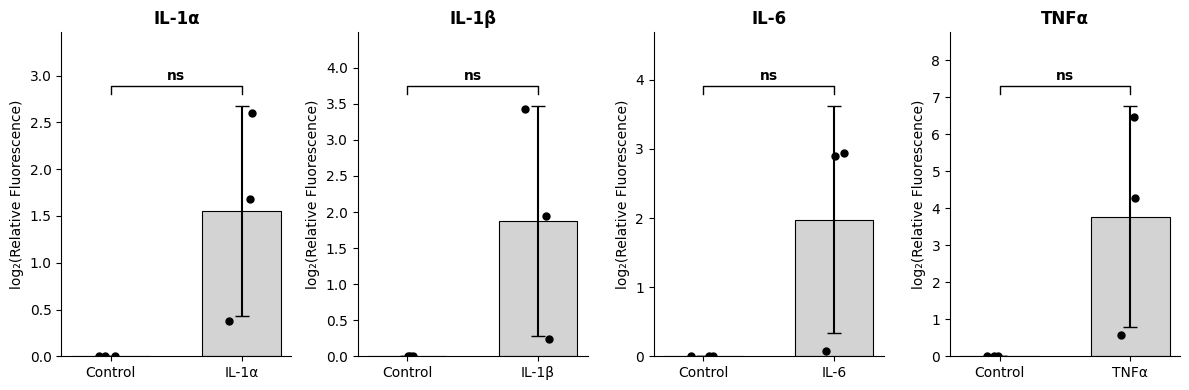

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


# ============================================================
# DATA
# Each treatment value is already normalized to its matched
# biological-replicate control:
#
# log2(Treatment / Control)
#
# Therefore, normalized Control = 0
# ============================================================

data = pd.DataFrame({
    "Control": [0, 0, 0],
    "IL-1α": [0.371968777, 1.684498174, 2.600904045],
    "IL-1β": [0.238159737, 1.948774677, 3.425654607],
    "IL-6":  [0.078002512, 2.941897045, 2.903784685],
    "TNFα":  [0.573735245, 4.279587823, 6.476256241],
})


# ============================================================
# SETTINGS
# ============================================================

cytokines = ["IL-1α", "IL-1β", "IL-6", "TNFα"]

bar_color = "#D3D3D3"

rng = np.random.default_rng(0)


# ============================================================
# SIGNIFICANCE STARS
# ============================================================

def get_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"


# ============================================================
# CALCULATE P-VALUES
#
# Since the data are normalized to each Bio Rep's control,
# Control = 0.
#
# Therefore, test whether the treatment mean differs from 0.
# ============================================================

p_values = {}

for cyt in cytokines:

    values = data[cyt].values

    t_stat, p = stats.ttest_1samp(
        values,
        popmean=0
    )

    p_values[cyt] = p

    print(
        f"{cyt}: "
        f"t = {t_stat:.3f}, "
        f"p = {p:.5f}, "
        f"{get_stars(p)}"
    )


# ============================================================
# CREATE PLOTS
# ============================================================

fig, axes = plt.subplots(
    1,
    len(cytokines),
    figsize=(12, 4)
)


for ax, cyt in zip(axes, cytokines):

    # --------------------------------------------------------
    # Control = 0
    # Treatment = measured normalized values
    # --------------------------------------------------------

    treatment = data[cyt].values

    groups = {
        "Control": np.zeros(len(treatment)),
        cyt: treatment
    }

    means = [
        values.mean()
        for values in groups.values()
    ]

    sds = [
        values.std(ddof=1)
        for values in groups.values()
    ]


    # --------------------------------------------------------
    # BAR PLOT
    # --------------------------------------------------------

    ax.bar(
        [0, 1],
        means,
        yerr=sds,
        capsize=5,
        color=bar_color,
        edgecolor="black",
        linewidth=0.8,
        width=0.6
    )


    # --------------------------------------------------------
    # INDIVIDUAL BIOLOGICAL REPLICATES
    # --------------------------------------------------------

    for i, values in enumerate(groups.values()):

        jitter = rng.uniform(
            -0.1,
            0.1,
            len(values)
        )

        ax.scatter(
            i + jitter,
            values,
            color="black",
            s=25,
            zorder=3
        )


    # --------------------------------------------------------
    # T-TEST SIGNIFICANCE
    # --------------------------------------------------------

    p = p_values[cyt]
    stars = get_stars(p)


    # Determine bracket height
    y_max = max(
        data[cyt].max(),
        max(
            mean + sd
            for mean, sd in zip(means, sds)
        )
    )

    if y_max <= 0:
        y_max = 1


    y_line = y_max * 1.08
    h = y_max * 0.03


    # Significance bracket
    ax.plot(
        [0, 0, 1, 1],
        [
            y_line - h,
            y_line,
            y_line,
            y_line - h
        ],
        color="black",
        linewidth=1
    )


    # Significance stars
    ax.text(
        0.5,
        y_line + h * 0.5,
        stars,
        ha="center",
        va="bottom",
        fontweight="bold"
    )


    # --------------------------------------------------------
    # AXIS FORMATTING
    # --------------------------------------------------------

    ax.set_xticks([0, 1])

    ax.set_xticklabels(
        ["Control", cyt]
    )

    ax.set_title(
        cyt,
        fontweight="bold"
    )

    ax.set_ylabel(
        "log₂(Relative Fluorescence)"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_ylim(
        0,
        y_line * 1.2
    )


# ============================================================
# FINAL FORMATTING
# ============================================================

plt.tight_layout()


# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "Cytokine_Barplots_ttest.png",
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# DISPLAY
# ============================================================

plt.show()